# Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Home Credit Default Risk Prediction using Random Forest

## Business Problem

Financial institutions need to assess the creditworthiness of loan applicants to reduce the risk of loan default. Home Credit aims to provide accessible loans while ensuring responsible lending decisions.

## Task

The goal of this project is to predict whether a loan applicant is likely to experience payment difficulties.

A Random Forest Classifier will be trained using applicant information to classify customers into two groups:

- **0:** Clients without payment difficulties.
- **1:** Clients with payment difficulties.

Since the dataset is imbalanced, particular attention will be given to identifying class 1 correctly.

### Dataset Description

The dataset (`application_data.csv`) contains information about loan applicants, including demographic, financial, and employment-related features.

Each row represents one loan application, and the `TARGET` column indicates whether the applicant experienced payment difficulties:

- **0:** No payment difficulties.
- **1:** Payment difficulties.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

### Dataset: application_data

The dataset contains **307,511 records and 122 columns**. Each record represents one loan application.

Important features include:

- **SK_ID_CURR:** Unique identifier of each loan application.
- **TARGET:** Target variable (0: no payment difficulties, 1: payment difficulties).
- **Demographic features:** CODE_GENDER, DAYS_BIRTH, CNT_CHILDREN, NAME_FAMILY_STATUS.
- **Financial features:** AMT_INCOME_TOTAL, AMT_CREDIT, AMT_ANNUITY, AMT_GOODS_PRICE.
- **Employment features:** DAYS_EMPLOYED, OCCUPATION_TYPE, ORGANIZATION_TYPE.
- **Housing features:** FLAG_OWN_CAR, FLAG_OWN_REALTY, NAME_HOUSING_TYPE.
- **External scores:** EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3.
- **Other features:** Phone and document flags, regional information, and credit bureau enquiry counts.

The `TARGET` column is the variable we aim to predict using a Random Forest classifier.

In [ ]:
application_train = pd.read_csv('/content/drive/MyDrive/ML/ML/تمرین دوم/Data/application_data.csv')
print("Data head:")
print(application_train.head())
print("Information:")
print(application_train.info())
print("Statistics:")
print(application_train.describe())
print("Shape:")
print(application_train.shape)

Data head:
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...                 0  

### 1.2 Check for missing value

In [ ]:
# check for missing data
# 1 checking missing data in application_train
total = application_train.isnull().sum().sort_values(ascending = False)
percent = (application_train.isnull().sum()/application_train.isnull().count()*100).sort_values(ascending = False)
missing_application_train_data  = pd.concat([total, percent], axis=1, keys=['Total', 'Missing Percent'])
print(missing_application_train_data.head(50))

                               Total  Missing Percent
COMMONAREA_AVG                214865        69.872297
COMMONAREA_MODE               214865        69.872297
COMMONAREA_MEDI               214865        69.872297
NONLIVINGAPARTMENTS_MEDI      213514        69.432963
NONLIVINGAPARTMENTS_MODE      213514        69.432963
NONLIVINGAPARTMENTS_AVG       213514        69.432963
FONDKAPREMONT_MODE            210295        68.386172
LIVINGAPARTMENTS_AVG          210199        68.354953
LIVINGAPARTMENTS_MEDI         210199        68.354953
LIVINGAPARTMENTS_MODE         210199        68.354953
FLOORSMIN_MODE                208642        67.848630
FLOORSMIN_AVG                 208642        67.848630
FLOORSMIN_MEDI                208642        67.848630
YEARS_BUILD_AVG               204488        66.497784
YEARS_BUILD_MODE              204488        66.497784
YEARS_BUILD_MEDI              204488        66.497784
OWN_CAR_AGE                   202929        65.990810
LANDAREA_MEDI               

### 1.3 Data Exploration

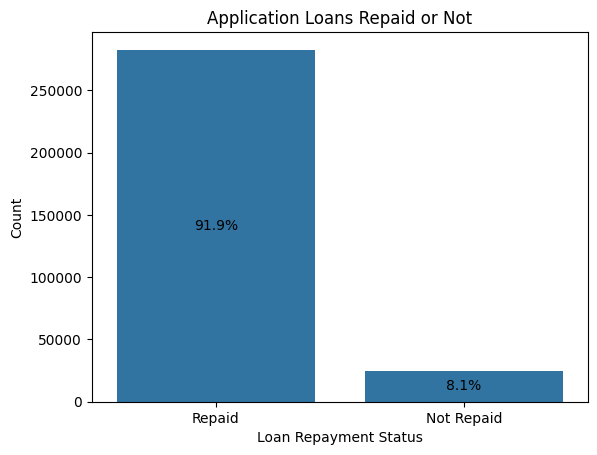

In [ ]:
# Distribution of Target variable

ax = sns.countplot(x="TARGET", data=application_train)
plt.title('Application Loans Repaid or Not')
plt.xlabel('Loan Repayment Status')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Repaid', 'Not Repaid'])

# Adding percentage text in the middle of the bars
total = len(application_train)
for p in ax.axes.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height() / total)
    x = p.get_x() + p.get_width() / 2
    y = p.get_height() / 2  # Set y to the middle of the bar's height
    ax.annotate(percentage, (x, y), ha='center', va='center')

plt.show()

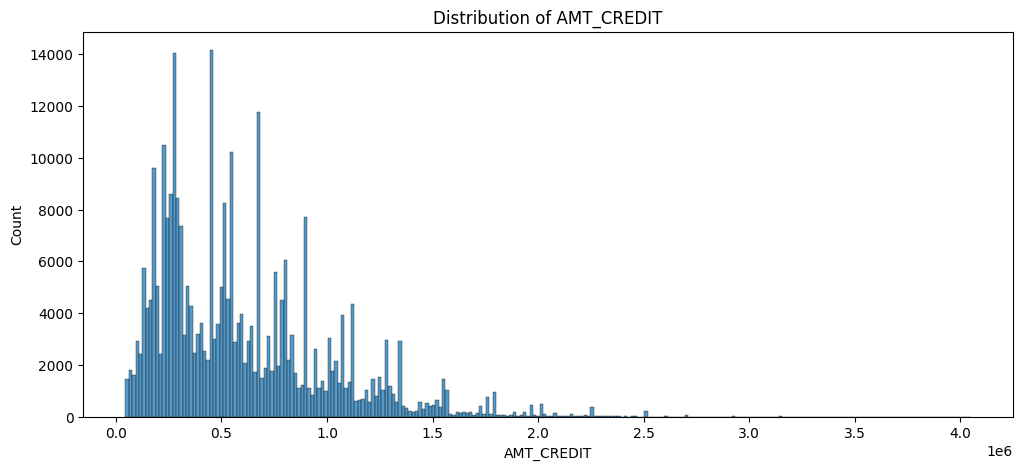

In [ ]:
# Distribution of AMT_CREDIT
plt.figure(figsize=(12,5))
plt.title("Distribution of AMT_CREDIT")
ax = sns.histplot(application_train["AMT_CREDIT"])
plt.show()

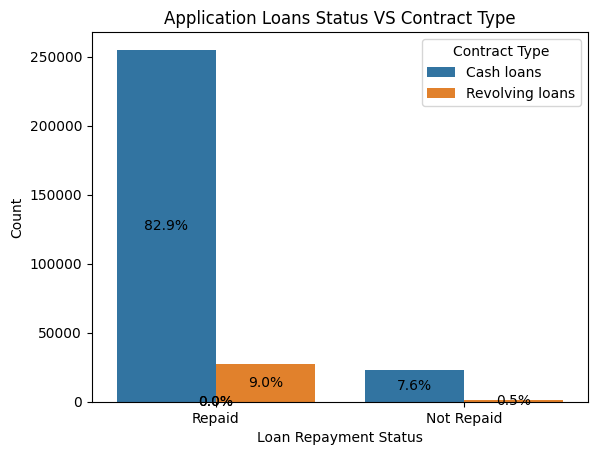

In [ ]:
# Relationship between Target and contract type

ax = sns.countplot(x ="TARGET", hue ='NAME_CONTRACT_TYPE',data=application_train)
plt.title('Application Loans Status VS Contract Type')
plt.xlabel('Loan Repayment Status')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Repaid', 'Not Repaid'])
plt.legend(title='Contract Type')
# Adding percentage text in the middle of the bars
total = len(application_train)
for p in ax.axes.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height() / total)
    x = p.get_x() + p.get_width() / 2
    y = p.get_height() / 2  # Set y to the middle of the bar's height
    ax.annotate(percentage, (x, y), ha='center', va='center')

plt.show()


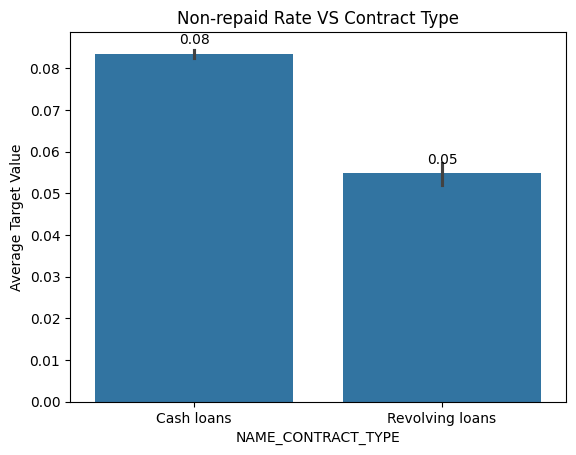

In [ ]:
# Calculate the average target value for each category
average_target = application_train.groupby('NAME_CONTRACT_TYPE')['TARGET'].mean()

# Create the bar plot
ax = sns.barplot(x='NAME_CONTRACT_TYPE', y='TARGET', data=application_train)

# Add the actual amount values on top of the bars
for p, amount in zip(ax.patches, average_target):
    ax.annotate(f'{amount:.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.title('Non-repaid Rate VS Contract Type')
plt.ylabel('Average Target Value')
plt.show()

# cash loans have higher non-repaid rate.

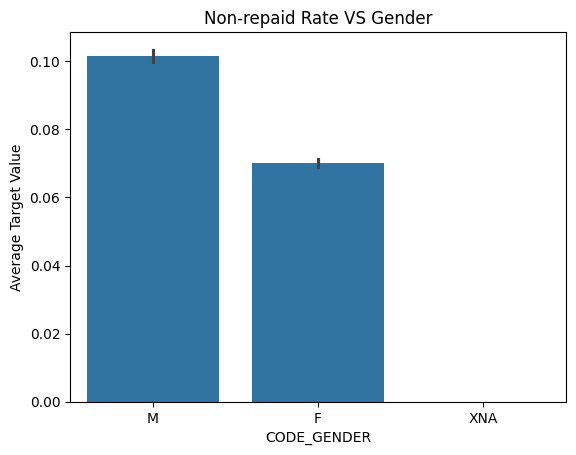

In [ ]:
# Non-repaid VS Gender

# Create the bar plot
ax = sns.barplot(x='CODE_GENDER', y='TARGET', data=application_train)


plt.title('Non-repaid Rate VS Gender')
plt.ylabel('Average Target Value')
plt.show()

# Male has higher not-repaid rate.

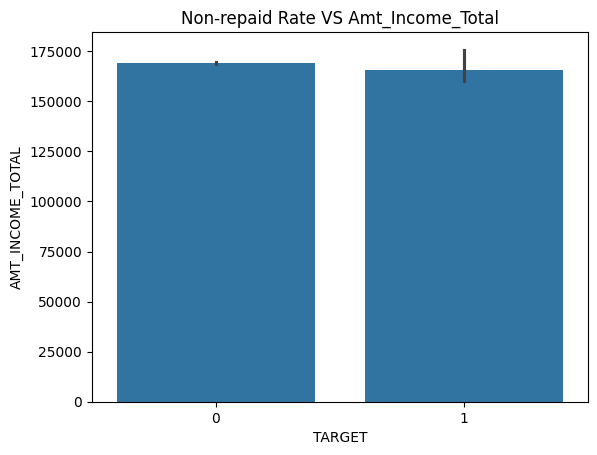

In [ ]:
# Non-repaid Rate VS AMT_INCOME_TOTAL

# Create the bar plot
sns.barplot(y='AMT_INCOME_TOTAL', x='TARGET', data=application_train)
plt.title('Non-repaid Rate VS Amt_Income_Total')
plt.show()

# not much different.


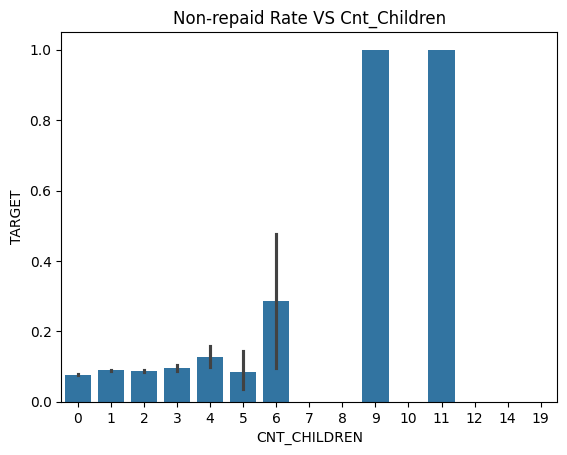

In [ ]:
# Non-repaid Rate VS Cnt_Children
sns.barplot(x ='CNT_CHILDREN', y='TARGET', data=application_train)
plt.title('Non-repaid Rate VS Cnt_Children')
plt.show()

# cnt = 5 has lowest rate.

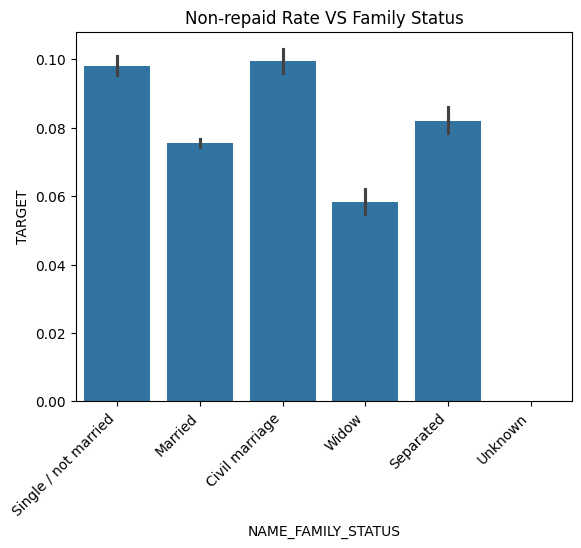

In [ ]:
# Non-repaid Rate VS Family Status

ax = sns.barplot(x='NAME_FAMILY_STATUS', y='TARGET', data=application_train)
# Rotate x-axis tick labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.title('Non-repaid Rate VS Family Status')
plt.show()

# lower non-repaid rate: widow, married.


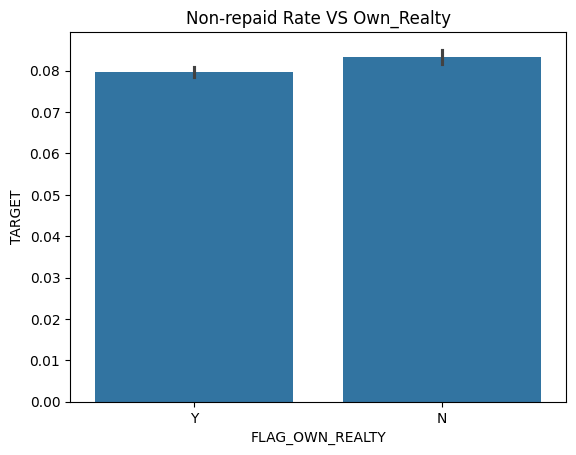

In [ ]:
# Non-repaid Rate VS Own_Realty
ax = sns.barplot(x='FLAG_OWN_REALTY', y='TARGET', data=application_train)
plt.title('Non-repaid Rate VS Own_Realty')
plt.show()

# not much different

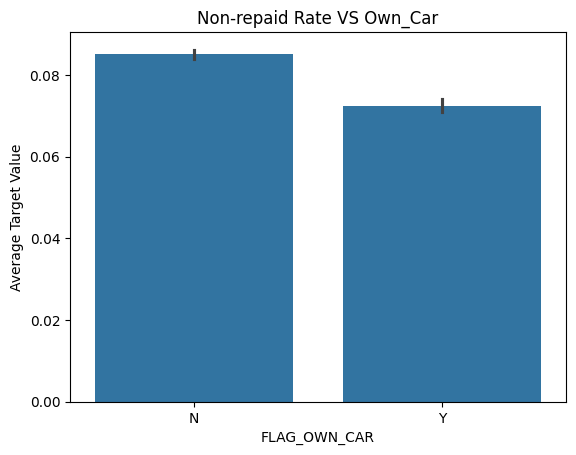

In [ ]:
# Non-repaid Rate VS Own_Car
ax = sns.barplot(x='FLAG_OWN_CAR', y='TARGET', data=application_train)
plt.title('Non-repaid Rate VS Own_Car')
plt.ylabel('Average Target Value')
plt.show()

# lower non-repaid rate: own-car


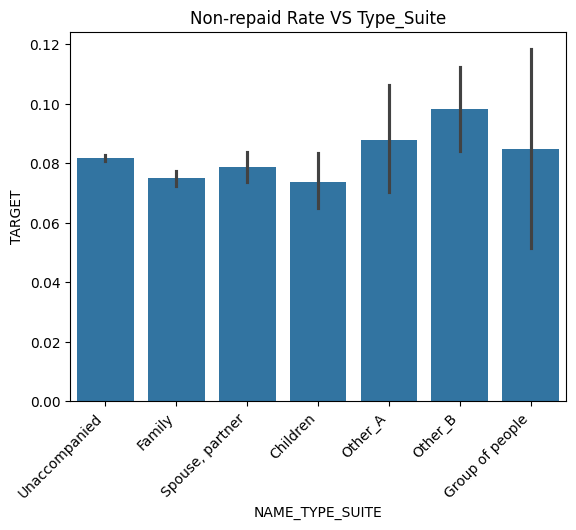

In [ ]:
# Non-repaid Rate VS Type_Suite
ax = sns.barplot(x='NAME_TYPE_SUITE', y='TARGET', data=application_train)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.title('Non-repaid Rate VS Type_Suite')
plt.show()

# lower for family

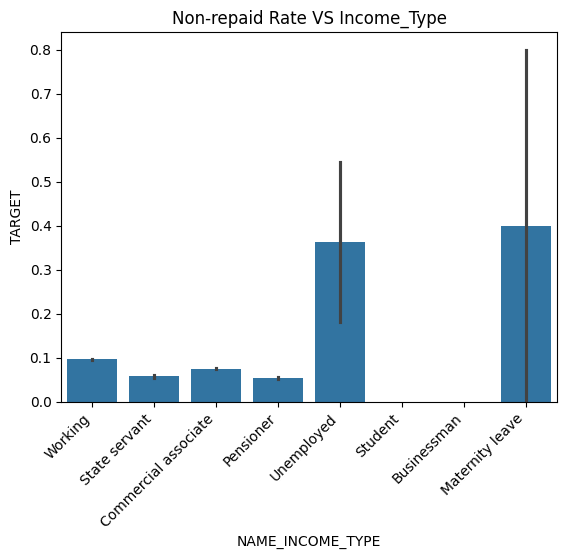

In [ ]:
ax = sns.barplot(x='NAME_INCOME_TYPE', y='TARGET', data=application_train)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.title('Non-repaid Rate VS Income_Type')
plt.show()

# higher for unemployed, matermity leave

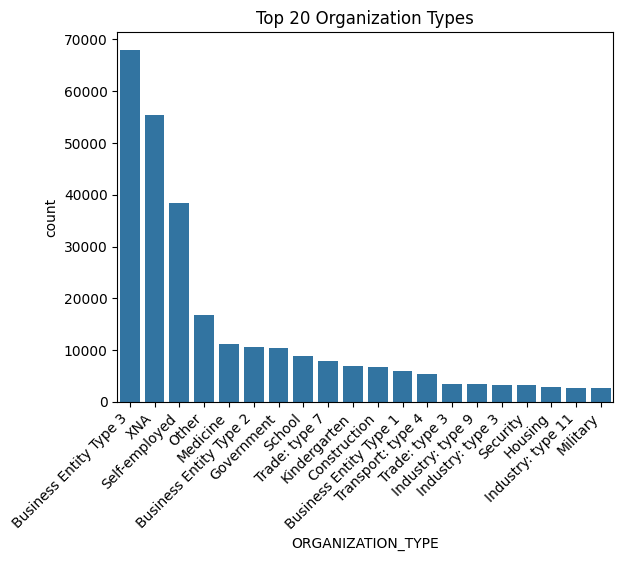

In [ ]:
# Get the top 20 categories based on count in descending order
top_categories = application_train['ORGANIZATION_TYPE'].value_counts().head(20).index

# Filter the dataset to include only the top categories
filtered_data = application_train[application_train['ORGANIZATION_TYPE'].isin(top_categories)]

# Create the count plot
ax = sns.countplot(x='ORGANIZATION_TYPE', data=filtered_data, order=top_categories)

# Rotate x-axis tick labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.title('Top 20 Organization Types')
plt.show()



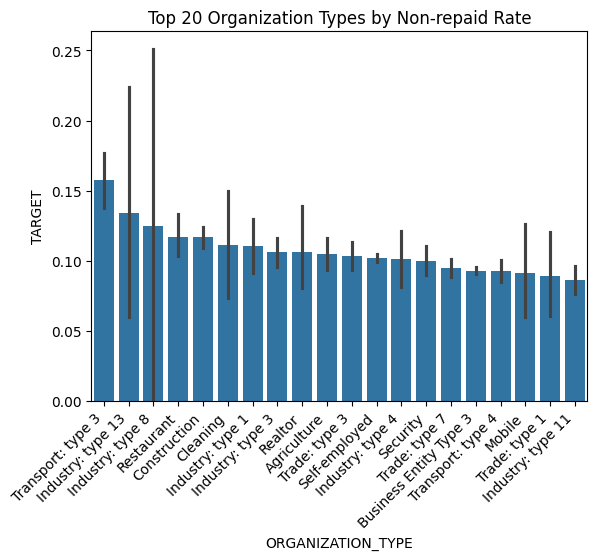

In [ ]:
# Calculate the average target value for each organization type
average_target_by_org = application_train.groupby('ORGANIZATION_TYPE')['TARGET'].mean()

# Get the top 20 organization types based on average target value in descending order
top_org_types = average_target_by_org.nlargest(20).index

# Filter the dataset to include only the top organization types
filtered_data = application_train[application_train['ORGANIZATION_TYPE'].isin(top_org_types)]

# Create the bar plot
ax = sns.barplot(x='ORGANIZATION_TYPE', y='TARGET', data=filtered_data, order=top_org_types)

# Rotate x-axis tick labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.title('Top 20 Organization Types by Non-repaid Rate')
plt.show()

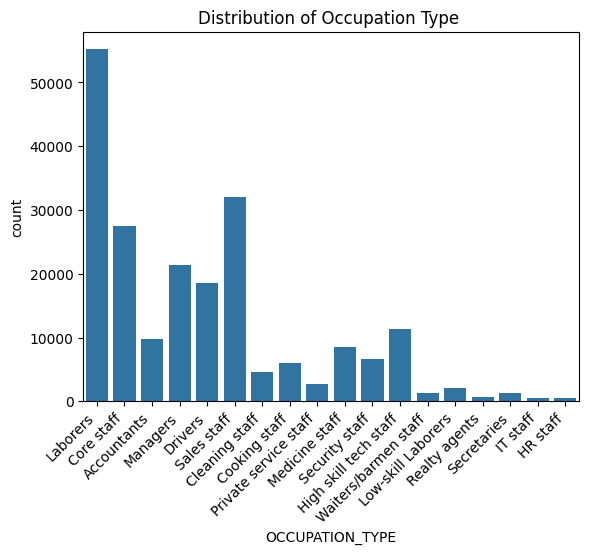

In [ ]:
ax = sns.countplot(x='OCCUPATION_TYPE', data=application_train)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.title('Distribution of Occupation Type ')
plt.show()

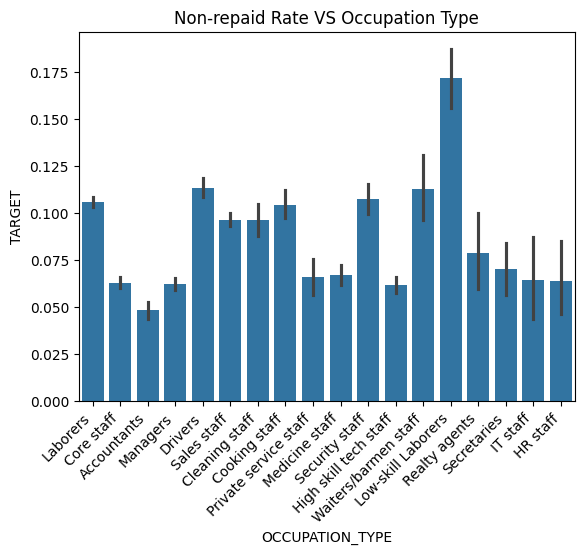

In [ ]:
ax = sns.barplot(x='OCCUPATION_TYPE', y='TARGET', data=application_train)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.title('Non-repaid Rate VS Occupation Type')
plt.show()
# highest: low-skill laborers

In [ ]:
#ext_cols

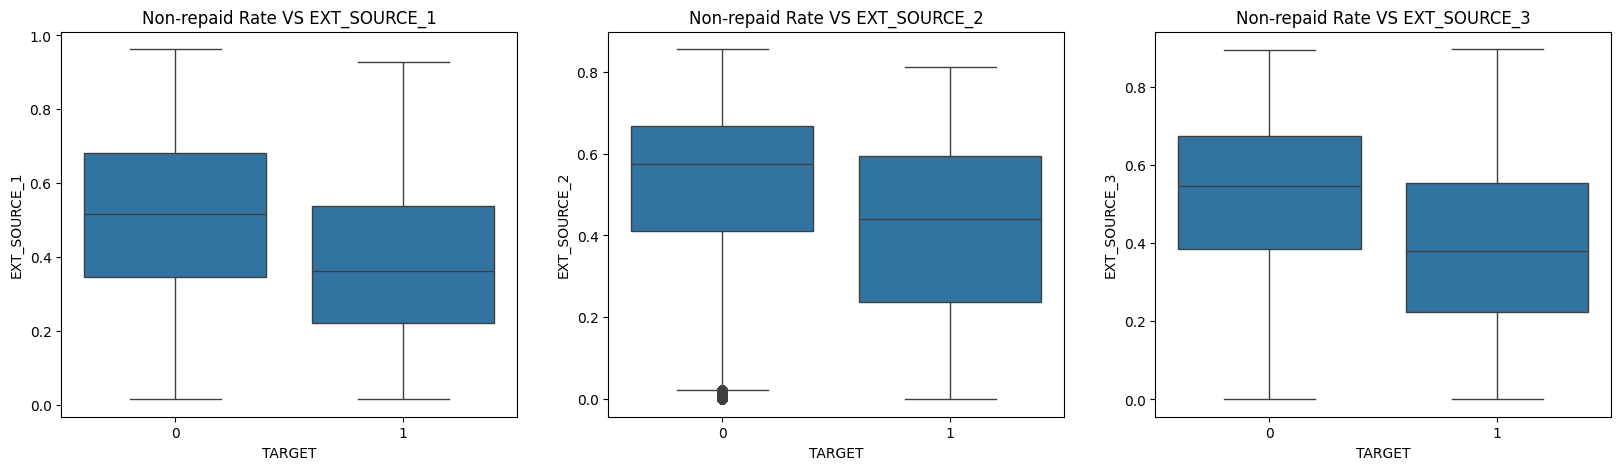

In [ ]:
# Non-repaid Rate VS EXT_SOURCE_1,2,3

fig, axes = plt.subplots(1,3,figsize=(20,5))
sns.boxplot(x='TARGET',y='EXT_SOURCE_1', data=application_train,ax=axes[0]).set(title ='Non-repaid Rate VS EXT_SOURCE_1')
sns.boxplot(x='TARGET',y='EXT_SOURCE_2', data=application_train,ax=axes[1]).set(title ='Non-repaid Rate VS EXT_SOURCE_2')
sns.boxplot(x='TARGET',y='EXT_SOURCE_3', data=application_train,ax=axes[2]).set(title ='Non-repaid Rate VS EXT_SOURCE_3')
plt.show()



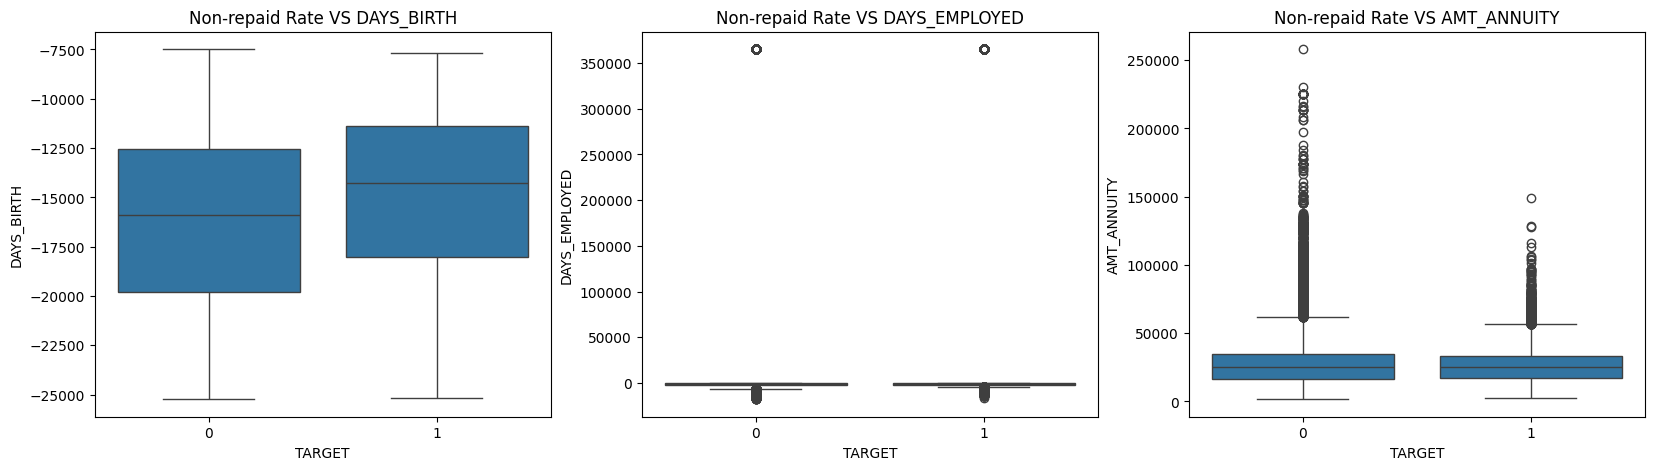

In [ ]:
# Non-repaid Rate VS DAYS_BIRTH,DAYS_EMPLOYED,AMT_ANNUITY

fig, axes = plt.subplots(1,3,figsize=(20,5))
sns.boxplot(x='TARGET',y='DAYS_BIRTH', data=application_train,ax=axes[0]).set(title ='Non-repaid Rate VS DAYS_BIRTH')
sns.boxplot(x='TARGET',y='DAYS_EMPLOYED', data=application_train,ax=axes[1]).set(title ='Non-repaid Rate VS DAYS_EMPLOYED')
sns.boxplot(x='TARGET',y='AMT_ANNUITY', data=application_train,ax=axes[2]).set(title ='Non-repaid Rate VS AMT_ANNUITY')
plt.show()

### 1.4 Data Preparation

Before training the Random Forest model, the dataset needs to be preprocessed.

**1. Handling Missing Values**

Missing values must be handled appropriately. Depending on the feature type, we can use imputation methods such as:
- Median imputation for numerical features.
- Most frequent value imputation for categorical features.

**2. Encoding Categorical Variables**

Machine learning models such as Random Forest require numerical input features. Therefore, categorical variables must be converted into numerical representations.

Two common encoding methods are:

- **Label Encoding:** Assigns an integer to each category.
- **One-Hot Encoding:** Creates separate binary columns for each category.

The appropriate encoding method will be selected based on the characteristics of the categorical features.

**3. Data Splitting**

The dataset will be divided into training and testing sets using `train_test_split`. We will use 75% of the data for training and 25% for evaluation while preserving the target class proportions through stratified sampling.


In [ ]:
# Number of each type of column
application_train.dtypes.value_counts()

,count
float64,65
int64,41
object,16


In [ ]:
# Number of unique classes in each object column
application_train.select_dtypes('object').apply(pd.Series.nunique, axis = 0)

,0
NAME_CONTRACT_TYPE,2
CODE_GENDER,3
FLAG_OWN_CAR,2
FLAG_OWN_REALTY,2
NAME_TYPE_SUITE,7
NAME_INCOME_TYPE,8
NAME_EDUCATION_TYPE,5
NAME_FAMILY_STATUS,6
NAME_HOUSING_TYPE,6
OCCUPATION_TYPE,18


In [ ]:
application_train.select_dtypes('object').apply(pd.Series.nunique, axis = 0)

,0
NAME_CONTRACT_TYPE,2
CODE_GENDER,3
FLAG_OWN_CAR,2
FLAG_OWN_REALTY,2
NAME_TYPE_SUITE,7
NAME_INCOME_TYPE,8
NAME_EDUCATION_TYPE,5
NAME_FAMILY_STATUS,6
NAME_HOUSING_TYPE,6
OCCUPATION_TYPE,18


In [ ]:
correlations = (
    application_train
    .select_dtypes(include=np.number)
    .corr()['TARGET']
    .sort_values()
)

print(correlations)

EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
DAYS_EMPLOYED                 -0.044932
FLOORSMAX_AVG                 -0.044003
                                 ...   
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, Length: 106, dtype: float64


In [ ]:
# Display correlations
print('Most Positive Correlations:\n', correlations.tail(20))
print('\nMost Negative Correlations:\n', correlations.head(20))

Most Positive Correlations:
 OBS_30_CNT_SOCIAL_CIRCLE       0.009131
CNT_FAM_MEMBERS                0.009308
CNT_CHILDREN                   0.019187
AMT_REQ_CREDIT_BUREAU_YEAR     0.019930
FLAG_WORK_PHONE                0.028524
DEF_60_CNT_SOCIAL_CIRCLE       0.031276
DEF_30_CNT_SOCIAL_CIRCLE       0.032248
LIVE_CITY_NOT_WORK_CITY        0.032518
OWN_CAR_AGE                    0.037612
DAYS_REGISTRATION              0.041975
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64

Most Negative Correlations:
 EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.15

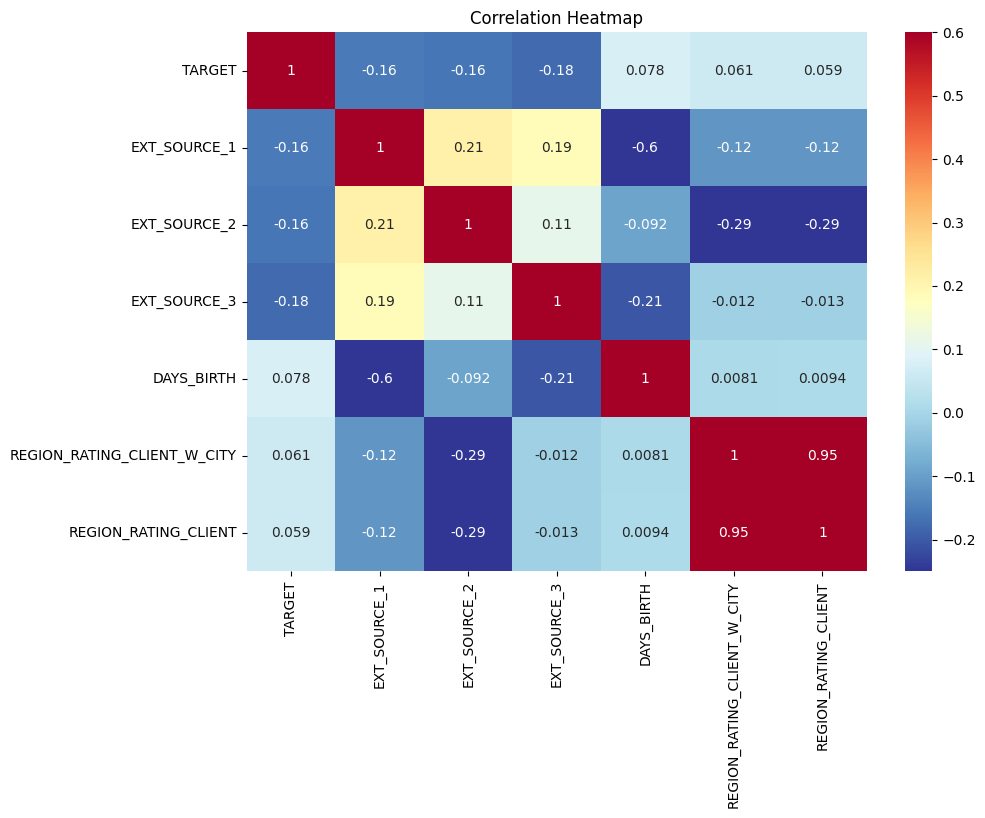

In [ ]:
ext_cols = [
    'TARGET',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'DAYS_BIRTH',
    'REGION_RATING_CLIENT_W_CITY',
    'REGION_RATING_CLIENT'
]

ext_data = application_train[ext_cols]
ext_data_corrs = ext_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    ext_data_corrs,
    cmap=plt.cm.RdYlBu_r,
    vmin=-0.25,
    vmax=0.6,
    annot=True
)
plt.title('Correlation Heatmap')
plt.show()

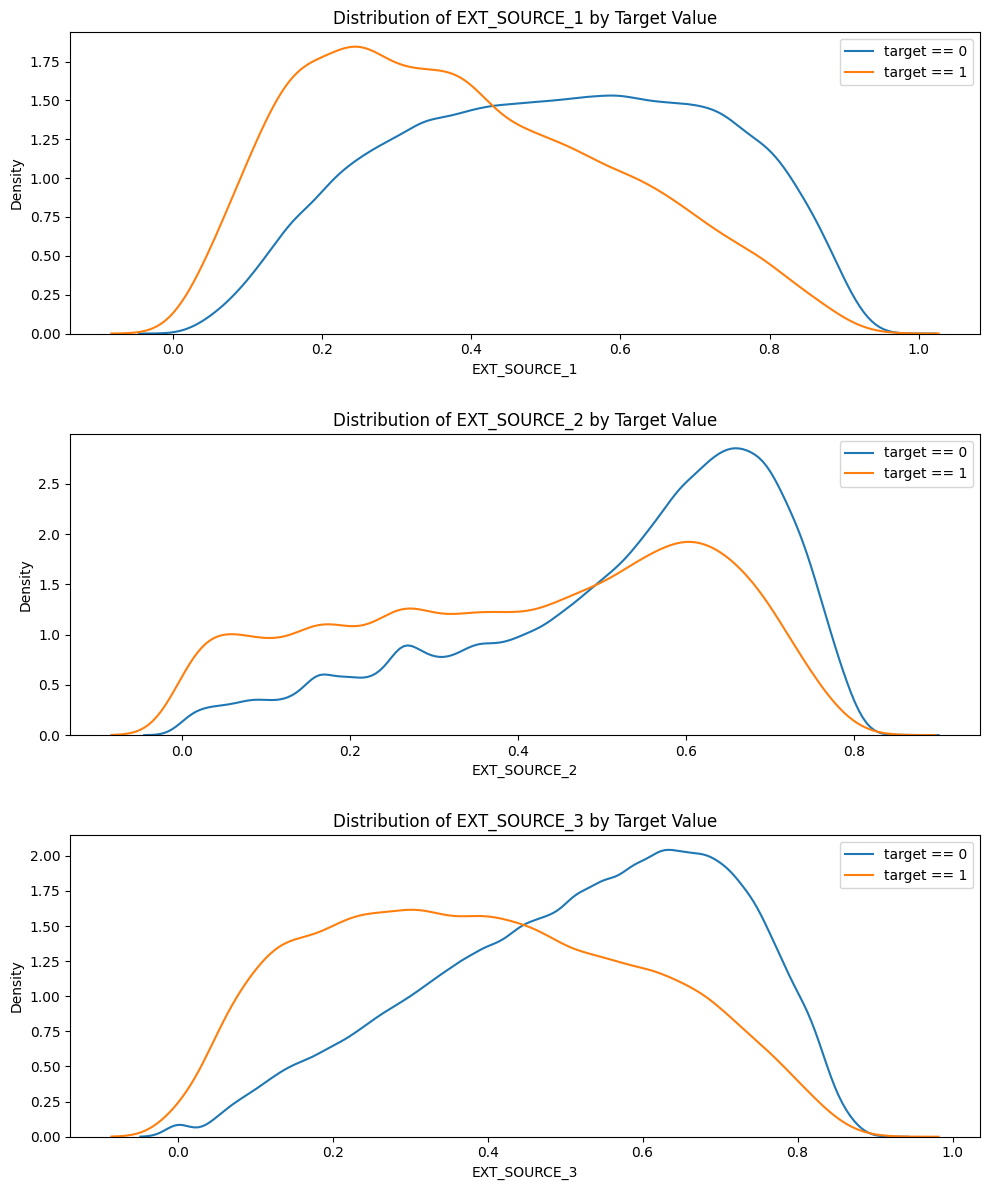

In [ ]:
plt.figure(figsize = (10, 12))

# iterate through the sources
for i, source in enumerate(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):

    # create a new subplot for each source
    plt.subplot(3, 1, i + 1)
    # plot repaid loans
    sns.kdeplot(application_train.loc[application_train['TARGET'] == 0, source], label = 'target == 0')
    # plot loans that were not repaid
    sns.kdeplot(application_train.loc[application_train['TARGET'] == 1, source], label = 'target == 1')

    # Label the plots
    plt.title('Distribution of %s by Target Value' % source)
    plt.xlabel('%s' % source); plt.ylabel('Density')

    # Show the legend.
    plt.legend()

plt.tight_layout(h_pad = 2.5)

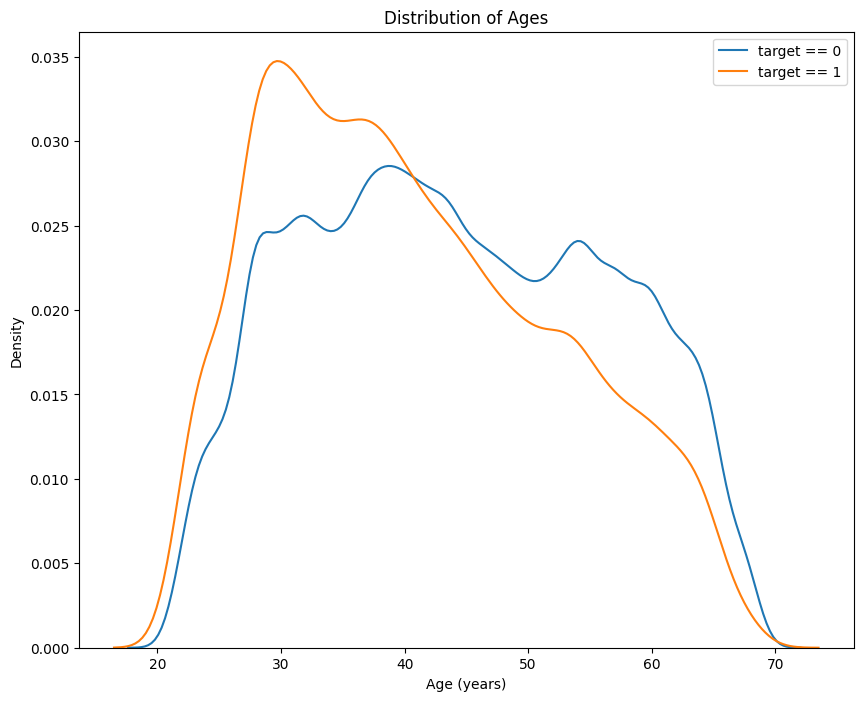

In [ ]:
plt.figure(figsize = (10, 8))


# KDE plot of loans that were repaid on time
sns.kdeplot(application_train.loc[application_train['TARGET'] == 0, 'DAYS_BIRTH'] / -365, label = 'target == 0')

# KDE plot of loans which were not repaid on time
sns.kdeplot(application_train.loc[application_train['TARGET'] == 1, 'DAYS_BIRTH'] / -365, label = 'target == 1')

# Labeling of plot
plt.xlabel('Age (years)'); plt.ylabel('Density'); plt.title('Distribution of Ages')
plt.legend()



## Preprocessing

In this section, we prepare the dataset for feature engineering and model training by splitting the data and handling missing values and categorical features.

Separate Features and Target

In [ ]:
X = application_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = application_train['TARGET']

Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in testing set:")
print(y_test.value_counts(normalize=True))

Training set: (230633, 120)
Testing set: (76878, 120)

Target distribution in training set:
TARGET
0    0.91927
1    0.08073
Name: proportion, dtype: float64

Target distribution in testing set:
TARGET
0    0.919275
1    0.080725
Name: proportion, dtype: float64


Identify Numerical and Categorical Features

In [ ]:
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 104
Categorical features: 16


Build Preprocessing Pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

Apply Preprocessing

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training set:", X_train_processed.shape)
print("Processed testing set:", X_test_processed.shape)

Processed training set: (230633, 244)
Processed testing set: (76878, 244)


## Part 2: Feature Engineering

Feature Engineering refers to the process of creating new features from existing data (feature construction) and selecting the most important features or applying dimensionality reduction techniques (feature selection).

There are many techniques we can use for both feature construction and feature selection.

- Polynomial Features
- Domain Knowledge Features

### 2.1 Polynomial features

Cell 1: Select Features

In [ ]:
poly_columns = [
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

X_train_poly = X_train[poly_columns].copy()
X_test_poly = X_test[poly_columns].copy()

print("Training data:", X_train_poly.shape)
print("Testing data:", X_test_poly.shape)

Training data: (230633, 3)
Testing data: (76878, 3)


Cell 2: Handle Missing Values

In [ ]:
from sklearn.impute import SimpleImputer

poly_imputer = SimpleImputer(strategy='median')

X_train_poly = poly_imputer.fit_transform(X_train_poly)
X_test_poly = poly_imputer.transform(X_test_poly)

print("Missing values in train:", np.isnan(X_train_poly).sum())
print("Missing values in test:", np.isnan(X_test_poly).sum())

Missing values in train: 0
Missing values in test: 0


Cell 3: Generate Polynomial Features

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly_transformer = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly_transformer.fit_transform(X_train_poly)
X_test_poly = poly_transformer.transform(X_test_poly)

print("Polynomial Features shape:", X_train_poly.shape)
print("Polynomial Features Test shape:", X_test_poly.shape)

Polynomial Features shape: (230633, 9)
Polynomial Features Test shape: (76878, 9)


Cell 4: Display Feature Names

In [ ]:
poly_feature_names = poly_transformer.get_feature_names_out(poly_columns)

print(poly_feature_names)

['EXT_SOURCE_1' 'EXT_SOURCE_2' 'EXT_SOURCE_3' 'EXT_SOURCE_1^2'
 'EXT_SOURCE_1 EXT_SOURCE_2' 'EXT_SOURCE_1 EXT_SOURCE_3' 'EXT_SOURCE_2^2'
 'EXT_SOURCE_2 EXT_SOURCE_3' 'EXT_SOURCE_3^2']


Cell 5: Check Correlation with Target

In [ ]:
poly_df = pd.DataFrame(
    X_train_poly,
    columns=poly_feature_names
)

poly_df['TARGET'] = y_train.reset_index(drop=True)

poly_corrs = poly_df.corr()['TARGET'].sort_values()

print("Most Negative Correlations:")
print(poly_corrs.head(10))

print("\nMost Positive Correlations:")
print(poly_corrs.tail(10))

Most Negative Correlations:
EXT_SOURCE_2 EXT_SOURCE_3   -0.193149
EXT_SOURCE_1 EXT_SOURCE_2   -0.166060
EXT_SOURCE_1 EXT_SOURCE_3   -0.163452
EXT_SOURCE_2                -0.159533
EXT_SOURCE_3                -0.155105
EXT_SOURCE_2^2              -0.148919
EXT_SOURCE_3^2              -0.141339
EXT_SOURCE_1                -0.098879
EXT_SOURCE_1^2              -0.091221
TARGET                       1.000000
Name: TARGET, dtype: float64

Most Positive Correlations:
EXT_SOURCE_2 EXT_SOURCE_3   -0.193149
EXT_SOURCE_1 EXT_SOURCE_2   -0.166060
EXT_SOURCE_1 EXT_SOURCE_3   -0.163452
EXT_SOURCE_2                -0.159533
EXT_SOURCE_3                -0.155105
EXT_SOURCE_2^2              -0.148919
EXT_SOURCE_3^2              -0.141339
EXT_SOURCE_1                -0.098879
EXT_SOURCE_1^2              -0.091221
TARGET                       1.000000
Name: TARGET, dtype: float64


In [ ]:
poly_corrs = poly_df.corr()['TARGET'].drop('TARGET').sort_values()

print("Most Negative Correlations:")
print(poly_corrs.head(5))

print("\nMost Positive Correlations:")
print(poly_corrs.tail(5))

Most Negative Correlations:
EXT_SOURCE_2 EXT_SOURCE_3   -0.193149
EXT_SOURCE_1 EXT_SOURCE_2   -0.166060
EXT_SOURCE_1 EXT_SOURCE_3   -0.163452
EXT_SOURCE_2                -0.159533
EXT_SOURCE_3                -0.155105
Name: TARGET, dtype: float64

Most Positive Correlations:
EXT_SOURCE_3     -0.155105
EXT_SOURCE_2^2   -0.148919
EXT_SOURCE_3^2   -0.141339
EXT_SOURCE_1     -0.098879
EXT_SOURCE_1^2   -0.091221
Name: TARGET, dtype: float64


### 2.2 Domain Knowledge Features

The following features are created using domain knowledge:

- **CREDIT_INCOME_PERCENT:** The ratio of the credit amount to the client's annual income.
- **ANNUITY_INCOME_PERCENT:** The ratio of the monthly loan annuity to the client's annual income.
- **CREDIT_TERM:** The estimated loan repayment period in months.
- **DAYS_EMPLOYED_PERCENT:** The ratio of the number of days employed to the client's age in days.

Cell 1: Create Domain Features

In [ ]:
def create_domain_features(df):
    df = df.copy()

    df['CREDIT_INCOME_PERCENT'] = (
        df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL'].replace(0, np.nan)
    )

    df['ANNUITY_INCOME_PERCENT'] = (
        df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL'].replace(0, np.nan)
    )

    df['CREDIT_TERM'] = (
        df['AMT_CREDIT'] / df['AMT_ANNUITY'].replace(0, np.nan)
    )

    df['DAYS_EMPLOYED_PERCENT'] = (
        df['DAYS_EMPLOYED'] / df['DAYS_BIRTH'].replace(0, np.nan)
    )

    return df


X_train = create_domain_features(X_train)
X_test = create_domain_features(X_test)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (230633, 124)
Testing set: (76878, 124)


Cell 2: Plot New Features

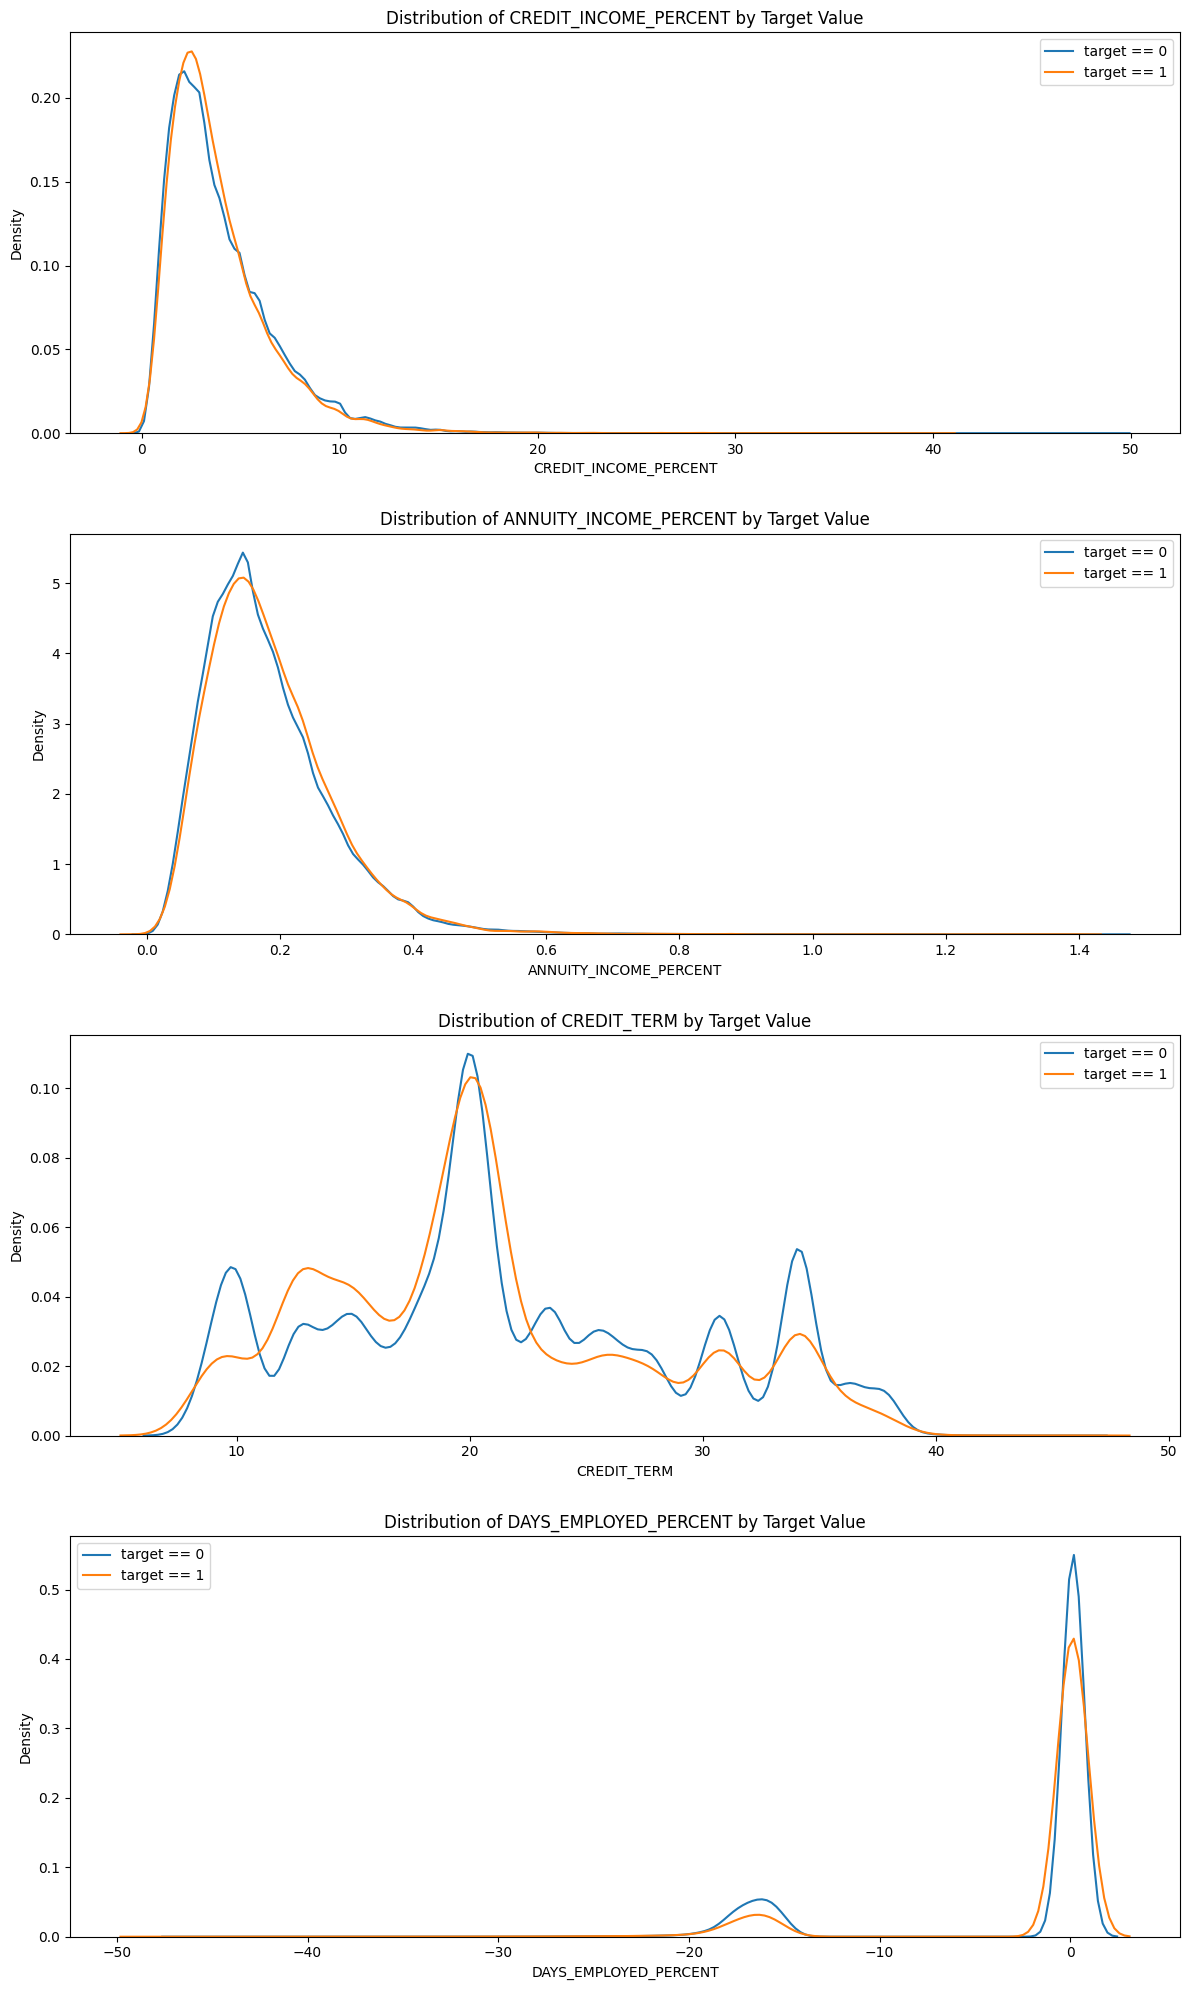

In [ ]:
plt.figure(figsize=(12, 20))

domain_features = [
    'CREDIT_INCOME_PERCENT',
    'ANNUITY_INCOME_PERCENT',
    'CREDIT_TERM',
    'DAYS_EMPLOYED_PERCENT'
]

for i, feature in enumerate(domain_features):

    plt.subplot(4, 1, i + 1)

    sns.kdeplot(
        X_train.loc[y_train == 0, feature],
        label='target == 0'
    )

    sns.kdeplot(
        X_train.loc[y_train == 1, feature],
        label='target == 1'
    )

    plt.title(f'Distribution of {feature} by Target Value')
    plt.xlabel(feature)
    plt.ylabel('Density')
    plt.legend()

plt.tight_layout(h_pad=2.5)
plt.show()

## Part 3:  Modeling

### Random Forest

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    bootstrap=True,
    max_depth=10,
    criterion='entropy',
    n_jobs=-1,
    class_weight='balanced'
)

rf.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=10, n_jobs=-1, random_state=42)

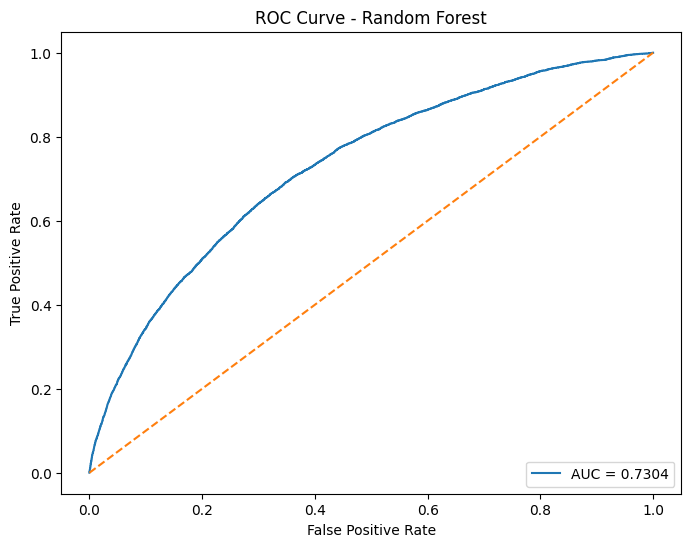

Best Threshold: 0.4737 with G-Mean: 0.6714
FPR: 0.3469, TPR: 0.6903


In [ ]:
from sklearn import metrics

y_pred_proba = rf.predict_proba(X_test_processed)[:, 1]

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()

# Calculate G-Mean
gmean = np.sqrt(tpr * (1 - fpr))

# Find Optimal Threshold
index = np.argmax(gmean)

thresholdOpt = round(thresholds[index], 4)
gmeanOpt = round(gmean[index], 4)
fprOpt = round(fpr[index], 4)
tprOpt = round(tpr[index], 4)

print(f'Best Threshold: {thresholdOpt} with G-Mean: {gmeanOpt}')
print(f'FPR: {fprOpt}, TPR: {tprOpt}')

In [ ]:
threshold2 = 0.0883

y_pred2 = (
    rf.predict_proba(X_test_processed)[:, 1] > threshold2
).astype(int)

rf_matrix = metrics.confusion_matrix(y_test, y_pred2)
print("Confusion Matrix:")
print(rf_matrix)

rf_report = metrics.classification_report(y_test, y_pred2)
print("\nClassification Report:")
print(rf_report)

Confusion Matrix:
[[   15 70657]
 [    0  6206]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.00      0.00     70672
           1       0.08      1.00      0.15      6206

    accuracy                           0.08     76878
   macro avg       0.54      0.50      0.07     76878
weighted avg       0.93      0.08      0.01     76878



In [ ]:
print(thresholdOpt)
print(gmeanOpt)

0.4737
0.6714


In [ ]:
threshold2 = thresholdOpt

y_pred2 = (
    rf.predict_proba(X_test_processed)[:, 1] >= threshold2
).astype(int)

rf_matrix = metrics.confusion_matrix(y_test, y_pred2)
print("Confusion Matrix:")
print(rf_matrix)

rf_report = metrics.classification_report(y_test, y_pred2)
print("\nClassification Report:")
print(rf_report)

Confusion Matrix:
[[46146 24526]
 [ 1922  4284]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.65      0.78     70672
           1       0.15      0.69      0.24      6206

    accuracy                           0.66     76878
   macro avg       0.55      0.67      0.51     76878
weighted avg       0.89      0.66      0.73     76878



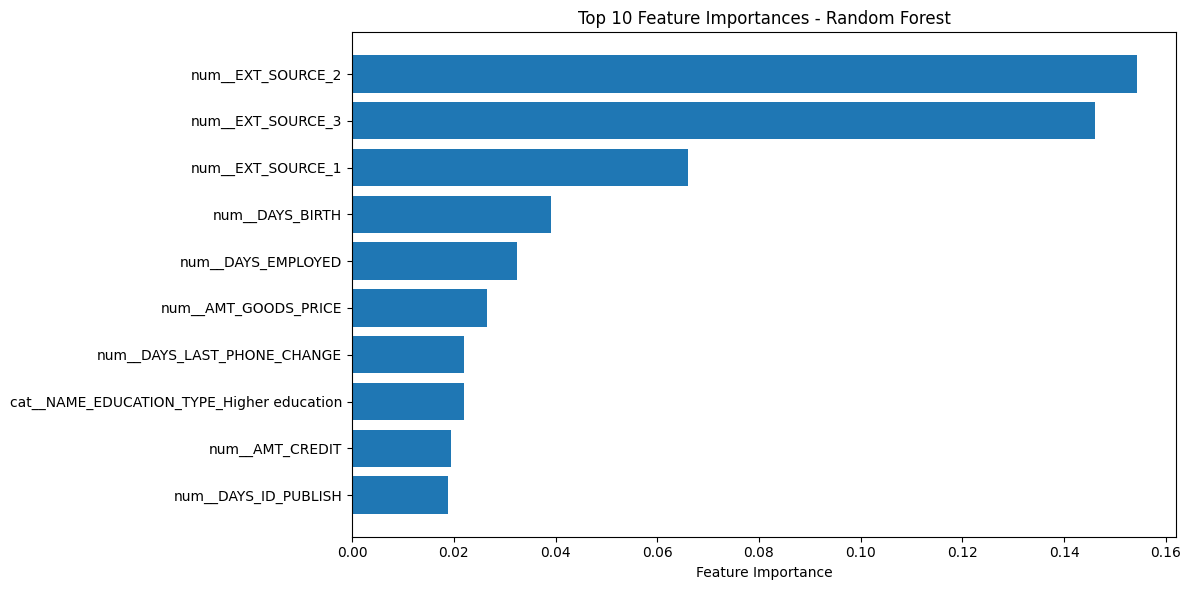

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

top_features = feature_importance.head(10)

plt.figure(figsize=(12, 6))
plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.title('Top 10 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()

## Part 4:  Models Evaluation

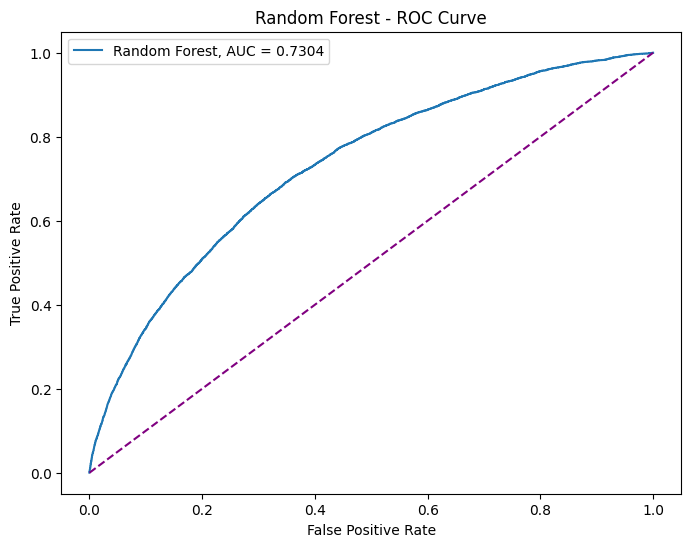

In [ ]:
plt.figure(figsize=(8, 6))

# Random Forest ROC Curve
y_pred_proba = rf.predict_proba(X_test_processed)[:, 1]

fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)

plt.plot(fpr, tpr, label=f"Random Forest, AUC = {auc:.4f}")

plt.plot([0, 1], [0, 1], color='purple', linestyle='--')

plt.title("Random Forest - ROC Curve")
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend()
plt.show()

# New section

In [ ]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

Training data: (230633, 248)
Testing data: (76878, 248)


## Hyperparameter tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_base = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5],
    'max_features': ['sqrt']
}

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=4,
    scoring='f1',
    cv=2,
    random_state=42,
    n_jobs=1,
    verbose=1
)

In [ ]:
random_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search.best_score_)

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Best Parameters:
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 15}

Best Cross-Validation F1 Score:
0.2682838147000949


In [ ]:
best_rf = RandomForestClassifier(
    **random_search.best_params_,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

best_rf.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=50, n_jobs=-1, random_state=42)

In [ ]:
y_pred_proba_best = best_rf.predict_proba(X_test_processed)[:, 1]

y_pred_best = best_rf.predict(X_test_processed)

print("Confusion Matrix:")
print(metrics.confusion_matrix(y_test, y_pred_best))

print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred_best))

print("ROC-AUC Score:",
      metrics.roc_auc_score(y_test, y_pred_proba_best))

Confusion Matrix:
[[58475 12197]
 [ 3260  2946]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.88     70672
           1       0.19      0.47      0.28      6206

    accuracy                           0.80     76878
   macro avg       0.57      0.65      0.58     76878
weighted avg       0.89      0.80      0.83     76878

ROC-AUC Score: 0.7284498080432362


In [ ]:
rf_original = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    bootstrap=True,
    max_depth=10,
    criterion='entropy',
    n_jobs=-1,
    class_weight='balanced'
)

rf_original.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=10, n_jobs=-1, random_state=42)

In [ ]:
y_pred_original = (
    rf_original.predict_proba(X_test_processed)[:, 1] >= 0.5
).astype(int)

print("Original Random Forest:")
print(metrics.classification_report(y_test, y_pred_original))

print("ROC-AUC:",
      metrics.roc_auc_score(
          y_test,
          rf_original.predict_proba(X_test_processed)[:, 1]
      ))

Original Random Forest:
              precision    recall  f1-score   support

           0       0.96      0.73      0.83     70672
           1       0.17      0.62      0.26      6206

    accuracy                           0.72     76878
   macro avg       0.56      0.67      0.54     76878
weighted avg       0.89      0.72      0.78     76878

ROC-AUC: 0.7365254926491419


## Feature Selection

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_original.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

top_10_features = feature_importance.head(10)

print(top_10_features)

                         Feature  Importance
29             num__EXT_SOURCE_3    0.145088
28             num__EXT_SOURCE_2    0.142217
27             num__EXT_SOURCE_1    0.057728
6                num__DAYS_BIRTH    0.035954
106             num__CREDIT_TERM    0.033327
7             num__DAYS_EMPLOYED    0.030725
107   num__DAYS_EMPLOYED_PERCENT    0.030028
77   num__DAYS_LAST_PHONE_CHANGE    0.021202
4           num__AMT_GOODS_PRICE    0.019367
2                num__AMT_CREDIT    0.018036


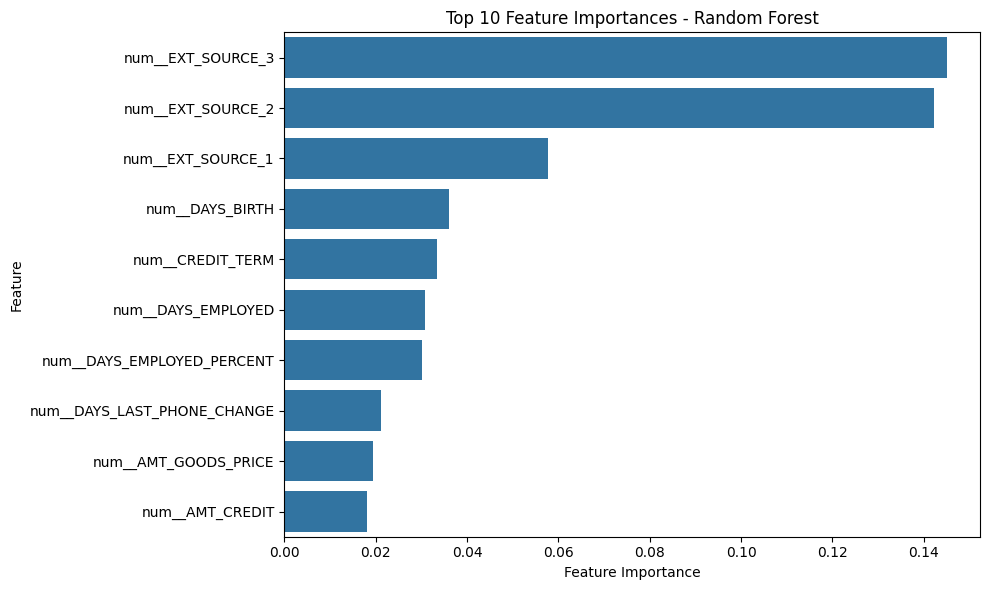

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Feature Importances - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
top_10_indices = feature_importance.head(10).index

X_train_top10 = X_train_processed[:, top_10_indices]
X_test_top10 = X_test_processed[:, top_10_indices]

print("Training data:", X_train_top10.shape)
print("Testing data:", X_test_top10.shape)

Training data: (230633, 10)
Testing data: (76878, 10)


In [ ]:
rf_top10 = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    bootstrap=True,
    max_depth=10,
    criterion='entropy',
    n_jobs=-1,
    class_weight='balanced'
)

rf_top10.fit(X_train_top10, y_train)

RandomForestClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=10, n_jobs=-1, random_state=42)

In [ ]:
y_pred_top10 = rf_top10.predict(X_test_top10)

y_pred_proba_top10 = rf_top10.predict_proba(X_test_top10)[:, 1]

print("Confusion Matrix:")
print(metrics.confusion_matrix(y_test, y_pred_top10))

print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred_top10))

print("ROC-AUC Score:",
      metrics.roc_auc_score(y_test, y_pred_proba_top10))

Confusion Matrix:
[[50889 19783]
 [ 2284  3922]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.72      0.82     70672
           1       0.17      0.63      0.26      6206

    accuracy                           0.71     76878
   macro avg       0.56      0.68      0.54     76878
weighted avg       0.89      0.71      0.78     76878

ROC-AUC Score: 0.7383350966488935


In [ ]:
y_proba_original = rf_original.predict_proba(X_test_processed)[:, 1]

fpr, tpr, thresholds = metrics.roc_curve(
    y_test, y_proba_original
)

gmean = np.sqrt(tpr * (1 - fpr))

best_index = np.argmax(gmean)
best_threshold = thresholds[best_index]

print("Optimal Threshold:", round(best_threshold, 4))
print("Best G-Mean:", round(gmean[best_index], 4))

Optimal Threshold: 0.4774
Best G-Mean: 0.6767


In [ ]:
y_pred_optimal = (
    y_proba_original >= best_threshold
).astype(int)

print("Confusion Matrix:")
print(metrics.confusion_matrix(y_test, y_pred_optimal))

print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred_optimal))

Confusion Matrix:
[[47413 23259]
 [ 1970  4236]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.67      0.79     70672
           1       0.15      0.68      0.25      6206

    accuracy                           0.67     76878
   macro avg       0.56      0.68      0.52     76878
weighted avg       0.90      0.67      0.75     76878



## Best threshod

In [ ]:
fpr_top10, tpr_top10, thresholds_top10 = metrics.roc_curve(
    y_test, y_pred_proba_top10
)

gmean_top10 = np.sqrt(tpr_top10 * (1 - fpr_top10))

best_index_top10 = np.argmax(gmean_top10)

best_threshold_top10 = thresholds_top10[best_index_top10]

print("Optimal Threshold:", round(best_threshold_top10, 4))
print("Best G-Mean:", round(gmean_top10[best_index_top10], 4))

Optimal Threshold: 0.4846
Best G-Mean: 0.6765


In [ ]:
y_pred_top10_opt = (
    y_pred_proba_top10 >= best_threshold_top10
).astype(int)

print("Confusion Matrix:")
print(metrics.confusion_matrix(y_test, y_pred_top10_opt))

print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred_top10_opt))

Confusion Matrix:
[[49069 21603]
 [ 2115  4091]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.81     70672
           1       0.16      0.66      0.26      6206

    accuracy                           0.69     76878
   macro avg       0.56      0.68      0.53     76878
weighted avg       0.89      0.69      0.76     76878



### Comparison: All Features vs. Top 10 Features

The Random Forest model trained on only the top 10 features achieved performance comparable to the model trained on all 248 features.

Despite using significantly fewer features, the reduced model maintained similar F1-score and G-Mean values, with a slightly higher accuracy. This suggests that the selected features capture most of the predictive information used by the original model.

Therefore, using all features may not be necessary for this dataset, as a smaller feature set can provide similar predictive performance with lower computational complexity.

# Part 6: Business Recommendations

The Random Forest model can support financial institutions in assessing loan default risk and identifying applicants who may experience difficulties in repayment.

### Key Recommendations

- **Risk Assessment:** Use the model to identify applicants with a higher likelihood of payment difficulties and prioritize them for further review.
- **Important Features:** Pay particular attention to external credit scores (`EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3`), which were among the most influential features in the model.
- **Threshold Optimization:** Adjust the classification threshold according to business priorities. A lower threshold may help identify more high-risk applicants, while increasing false positive predictions.
- **Model Limitations:** The model has relatively low precision for class 1, meaning many applicants predicted as high-risk may not actually experience payment difficulties. Therefore, predictions should support human decision-making rather than determine loan approval or rejection automatically.

### Conclusion

The experiments show that Random Forest can identify patterns associated with loan repayment difficulties. Furthermore, the top 10 features achieved performance comparable to the full feature set, suggesting that a smaller set of features may be sufficient for this prediction task.

However, further improvements in precision, model validation, and fairness assessment are necessary before considering real-world deployment.

# Part 7: Final Model Comparison

The following table summarizes the performance of the Random Forest models under different configurations.

| Metric | Original RF (0.5) | Original RF (Optimal) | Tuned RF (0.5) | Top 10 RF (0.5) | Top 10 RF (Optimal) |
|---|---:|---:|---:|---:|---:|
| Number of Features | 248 | 248 | 248 | 10 | 10 |
| Accuracy | 0.72 | 0.67 | 0.80 | 0.71 | 0.69 |
| Precision (Class 1) | 0.17 | 0.15 | 0.19 | 0.17 | 0.16 |
| Recall (Class 1) | 0.62 | 0.68 | 0.47 | 0.63 | 0.66 |
| F1-score (Class 1) | 0.26 | 0.25 | 0.28 | 0.26 | 0.26 |
| ROC-AUC | 0.7365 | — | 0.7284 | 0.7383 | — |
| G-Mean | — | 0.6767 | — | — | 0.6765 |

### Final Conclusion

- The tuned Random Forest achieved the highest accuracy and F1-score for class 1, but its recall was lower.
- Optimizing the classification threshold improved the recall of the original and top 10 feature models.
- The top 10 feature model achieved performance comparable to the original model while using significantly fewer features.
- Overall, the best model depends on the evaluation metric and the business objective. For identifying applicants at risk of payment difficulties, recall is particularly important.